# 13 · De la densité à une pièce imprimable

*Notebook 13 du cours. Il suppose le notebook 9 (densité projetée $\bar\rho$) et le notebook 12 (auto-support).*

Le résultat de l'optimisation est un **tableau de nombres** $\bar\rho_e\in[0,1]$, un par élément. Une imprimante, elle, lit un **maillage de surface** (un fichier STL : des triangles) qui décrit une pièce dont chaque point est soit plein soit vide. Entre les deux il y a quatre questions, chacune avec son piège :

1. **Où mettre la frontière ?** (le seuil) ;
2. **Comment dessiner cette frontière, lisse, à partir d'une grille ?** (*marching squares* en 2D, *marching cubes* en 3D) ;
3. **Le fichier est-il une pièce ?** (surface fermée, orientée, normales vers l'extérieur) ;
4. **Peut-on l'imprimer ?** (épaisseur minimale) ;

et une cinquième, honnête : **la pièce extraite est-elle aussi bonne que ce que l'optimiseur croyait ?**

**Plan.**
1. Ce que contient $\bar\rho$ et le choix du seuil ;
2. Marching squares : le contour 2D ;
3. Marching tetrahedra : la surface 3D, fermée par construction ;
4. Le fichier STL, et une console extrudée ;
5. L'épaisseur minimale : rayon du filtre contre largeur réelle ;
6. Ce que coûtent le seuillage et le lissage ;
7. Bilan.

**Code promu dans `src`.** `io/mesh.py` : `marching_squares`, `polygon_area`, `marching_tetrahedra`, `mesh_report`, `face_normals`, `write_stl`, `read_stl`, `thin_fraction`, `extrude`. Contrats : C-EXP-01 à 05 (nouveaux).

**Un écart par rapport au plan.** Le plan annonçait *marching cubes*. On implémente les **tétraèdres** (*marching tetrahedra*), pour une raison précise expliquée au §3 : le même principe, sans la table de 256 cas du cube et sans ses ambiguïtés, et une surface fermée **par construction**.

In [1]:
import sys, math, time, tempfile, struct
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import ndimage
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
sys.path.insert(0, str(RACINE / "tests"))

from aeroptimizer.fem import elements as el
from aeroptimizer.fem.adjoint import solve_spd
from aeroptimizer.fem.bc import build_case
from aeroptimizer.fem.operators import StructuredFEOperator
from aeroptimizer.fem.solvers import ScipyDirect
from aeroptimizer.grid import Connectivity, Grid
from aeroptimizer.io.mesh import (disk, extrude, face_normals, marching_squares, marching_tetrahedra,
                                  mesh_report, polygon_area, read_stl, thin_fraction, write_stl)
from aeroptimizer.materials import Orthotropic
from aeroptimizer.optim.continuation import Schedule
from aeroptimizer.optim.loop import run
from aeroptimizer.optim.mma import MMA
from aeroptimizer.problem import ComplianceProblem
from aeroptimizer.topopt.density import simp

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def montre(ax, rho, titre="", cmap="gray_r"):
    ax.imshow(np.asarray(rho).T, origin="lower", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(titre, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

def optimise_console(R=3.0, shape=(60, 30), volfrac=0.4):
    pb = ComplianceProblem("cantilever", shape, volfrac=volfrac, R=R, normalize=True)
    r = run(pb, MMA(), Schedule(p=(3.0, 3.0), beta=(1.0, 16.0), beta_s=(1.0, 1.0), every=50), max_iter=300, tol=1e-3)
    return pb, pb.rho_bar(torch.from_numpy(r.x)).detach().numpy().reshape(shape)

def compliance_fe(rho, p=1.0, eps_s=1e-9, h=(1.0, 1.0), charge_sur_solide=False):
    # compliance de la console (charge répartie, bien posée : converge avec le maillage) pour un champ rho.
    # charge_sur_solide=True : la charge n'est appliquée qu'aux nœuds qui touchent une cellule pleine
    # (rho > 0,5), le total restant 1 ; par défaut elle est appliquée à tous les nœuds du bord, comme
    # dans l'optimisation (DistributedForce ignore la densité).
    shape = rho.shape
    g = Grid(shape, h); fixed, load, _ = build_case("cantilever", g)
    Ke0 = el.elasticity_ke0(2, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(2))
    op = StructuredFEOperator(g, Connectivity(g, 2), Ke0, 2, fixed)
    f = load.assemble(torch.ones(shape))
    if charge_sur_solide:
        plein = torch.from_numpy((np.asarray(rho) > 0.5).astype(float)).reshape(-1)
        touche = torch.zeros(g.n_dofs(2)).index_add_(0, op.edof.reshape(-1), plein[:, None].expand(-1, 8).reshape(-1))
        f = f * (touche > 0).double(); f = f / f.abs().sum()
    u = solve_spd(op, simp(torch.from_numpy(np.asarray(rho, float)).reshape(-1), p, eps_s), f, ScipyDirect())
    return float(f @ u)

## 1. Ce que contient $\bar\rho$, et où mettre le seuil

On optimise une console $60\times30$ (fraction volumique $0{,}4$, rayon de filtre $R=3$, continuation en $\beta$ de 1 à 16, MMA) : c'est le cas du notebook 12, sans filtre de surplomb. La charge est répartie sur le bord libre, ce qui rend la compliance bien définie quand on raffine (une charge ponctuelle donne une compliance qui diverge avec le maillage, ce qui fausserait la comparaison du §6).

optimisation : 2.9 s ; volume 0.4000 ; cellules grises (0,1 < rho < 0,9) : 6.1 %


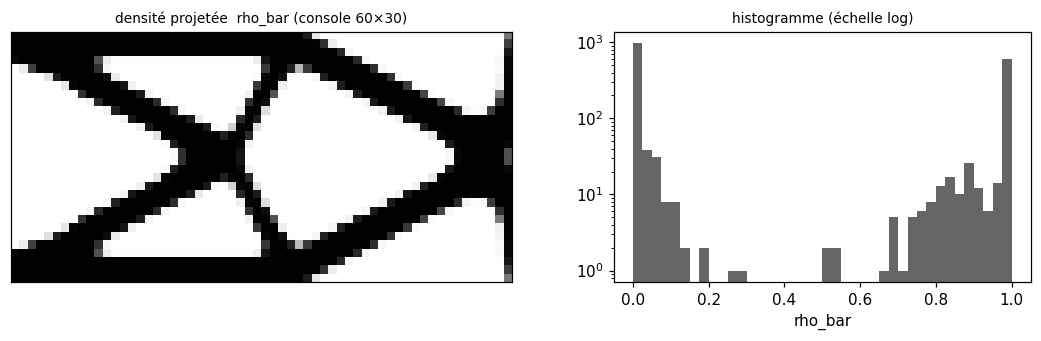

In [2]:
t0 = time.time()
pb, rb = optimise_console()
print(f"optimisation : {time.time()-t0:.1f} s ; volume {rb.mean():.4f} ; cellules grises (0,1 < rho < 0,9) : {100*((rb>0.1)&(rb<0.9)).mean():.1f} %")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [2, 1.4]})
montre(axs[0], rb, "densité projetée  rho_bar (console 60×30)")
axs[1].hist(rb.ravel(), bins=40, color="0.4"); axs[1].set_yscale("log"); axs[1].set_xlabel("rho_bar"); axs[1].set_title("histogramme (échelle log)", fontsize=9)
plt.tight_layout(); plt.show()

Après la continuation en $\beta$, la densité est presque binaire : l'histogramme est concentré en $0$ et en $1$ et quelques pour cent des cellules sont grises. Le **seuil** transforme ce qui reste en plein/vide. Trois critères pour le choisir, qui peuvent se contredire :

- **le volume** : le volume de la pièce seuillée doit rester proche de la contrainte ;
- **la cohérence avec la projection** : la projection de Heaviside est centrée en $\eta=0{,}5$, donc le seuil naturel est $0{,}5$ ;
- **la connexité** : un seuil trop haut peut **couper** une membrure fine, et la pièce devient un mécanisme.

On mesure le deuxième et le troisième sur la compliance de la pièce binaire.

compliance de l'optimiseur (rho_bar continu, SIMP p=3) : 83.65   volume 0.4000

 seuil   volume  charge sur tout le bord   charge sur le solide
  0.20   0.4089                     80.8                  80.80
  0.25   0.4089                     80.8                  80.80
  0.30   0.4078                    80.92                  80.92
  0.35   0.4078                    80.92                  80.92
  0.40   0.4078                    80.92                  80.92
  0.45   0.4078                    80.92                  80.92
  0.50   0.4078                    80.92                  80.92
  0.55   0.4056                5.225e+06                  80.71   <- nœuds chargés orphelins
  0.60   0.4056                5.225e+06                  80.71   <- nœuds chargés orphelins
  0.65   0.4056                5.225e+06                  80.71   <- nœuds chargés orphelins
  0.70   0.4022                6.277e+06                  81.41   <- nœuds chargés orphelins
  0.75   0.3989                6.277

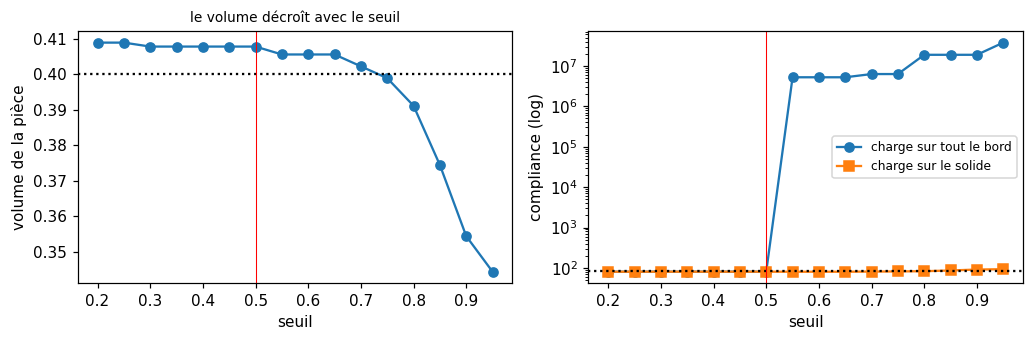

In [3]:
seuils = np.round(np.arange(0.2, 0.96, 0.05), 2)
vols = [(rb > s).mean() for s in seuils]
C_cst = [compliance_fe((rb > s).astype(float)) for s in seuils]                            # charge sur tout le bord
C_sol = [compliance_fe((rb > s).astype(float), charge_sur_solide=True) for s in seuils]    # charge sur le solide
C_cont = compliance_fe(rb, p=3.0)                      # ce que l'optimiseur évalue : SIMP p=3 sur rho_bar
print(f"compliance de l'optimiseur (rho_bar continu, SIMP p=3) : {C_cont:.2f}   volume {rb.mean():.4f}\n")
print(f"{'seuil':>6} {'volume':>8} {'charge sur tout le bord':>24} {'charge sur le solide':>22}")
for s, v, c1, c2 in zip(seuils, vols, C_cst, C_sol):
    print(f"{s:>6.2f} {v:>8.4f} {c1:>24.4g} {c2:>22.2f}" + ("   <- nœuds chargés orphelins" if c1 > 100 * C_cont else ""))
orph = (rb > 0.5) & ~(rb > 0.55)
print("\ncellules qui disparaissent entre les seuils 0,50 et 0,55 :", [tuple(map(int, c)) for c in np.argwhere(orph)], "  (le bord chargé est x = 59)")
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].plot(seuils, vols, "o-"); ax[0].axhline(0.4, color="k", ls=":"); ax[0].axvline(0.5, color="r", lw=0.7)
ax[0].set_xlabel("seuil"); ax[0].set_ylabel("volume de la pièce"); ax[0].set_title("le volume décroît avec le seuil", fontsize=9)
ax[1].semilogy(seuils, C_cst, "o-", label="charge sur tout le bord"); ax[1].semilogy(seuils, C_sol, "s-", label="charge sur le solide")
ax[1].axhline(C_cont, color="k", ls=":"); ax[1].axvline(0.5, color="r", lw=0.7)
ax[1].set_xlabel("seuil"); ax[1].set_ylabel("compliance (log)"); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Lecture.**
- **Colonne de gauche (charge sur tout le bord).** La compliance explose dès le seuil $0{,}55$, mais ce n'est **pas** la structure qui se casse : la pièce reste en un seul morceau. Les quatre cellules qui disparaissent sont des cellules du **bord chargé** (leurs $\bar\rho$ valent $0{,}515$ à $0{,}531$, juste au-dessus de $0{,}5$) ; deux d'entre elles, $(59,0)$ et $(59,29)$, sont les seules à porter les nœuds d'angle du bord chargé. La charge répartie, appliquée à *tous* les nœuds du bord quelle que soit la densité, reste accrochée à des nœuds qui n'ont plus aucune cellule pleine : une charge sur un nœud sans rigidité donne un déplacement énorme. C'est un artefact du modèle de charge, pas de la géométrie, mais il mérite d'être su : le même modèle est utilisé dans l'optimisation, qui doit donc garder de la matière en chaque nœud chargé.
- **Colonne de droite (charge seulement sur le solide).** La compliance varie **doucement** avec le seuil : $80{,}9$ à $0{,}5$, $91{,}5$ à $0{,}9$, au fur et à mesure que le volume baisse. Aucun seuil n'est catastrophique ; le choix est un compromis volume contre rigidité.
- **Le seuil à $0{,}5$** est le seuil de la projection ($\eta=0{,}5$), donc celui pour lequel $\bar\rho$ a été optimisé. Un seuil ajusté au volume exact ($\approx0{,}75$ ici) retire $2\,\%$ de volume par rapport à $0{,}5$ et la compliance monte de $1{,}4\,\%$ : on ne gagne rien à s'en écarter. L'écart de volume résiduel se règle en amont, dans l'optimisation.

## 2. Marching squares : le contour 2D

On voit $\bar\rho$ comme les valeurs d'une fonction en des **points** (les centres des éléments) ; on cherche la courbe $\{\bar\rho=0{,}5\}$. Chaque carré formé par quatre points voisins a quatre coins « dedans » ($\bar\rho>0{,}5$) ou « dehors » : $2^4=16$ cas. Dans chaque cas, le contour traverse certaines arêtes du carré (celles dont les deux bouts diffèrent), et on place le point de croisement par **interpolation linéaire** :

$$
t=\frac{\ell-v_a}{v_b-v_a},\qquad \mathbf p=\mathbf p_a+t\,(\mathbf p_b-\mathbf p_a),
$$

où $\ell=0{,}5$ est le niveau. Le champ vaut exactement $\ell$ en $\mathbf p$ si on interpole linéairement. C'est ce qui rend le contour **plus fin que la grille** : une cellule à $\bar\rho=0{,}6$ place la frontière près du bord de la cellule ; une cellule à $0{,}9$, plus loin.

Un carré a 16 cas, mais seulement 4 sont différents à rotation et complément près : coin isolé (1 segment), deux coins voisins (1 segment), trois coins (1 segment) et le **cas ambigu**, deux coins diagonaux. Là, deux dessins sont possibles : les coins « dedans » sont reliés (leurs régions fusionnent), ou ils sont séparés. On tranche avec la **valeur au centre** (moyenne des quatre coins) : si elle dépasse le niveau, la matière est connectée. C'est un choix, pas une vérité, mais il est cohérent d'un carré à l'autre.

Les segments sont ensuite chaînés en **boucles fermées** grâce aux arêtes qu'ils partagent, et chaque boucle est orientée avec la matière à gauche : les contours extérieurs tournent dans le sens trigonométrique, les trous dans le sens horaire. L'aire signée (formule du lacet) additionne alors les extérieurs et soustrait les trous.

In [4]:
# Validation 1 : un disque lisse de rayon 15 cellules, puis une couronne (un trou)
def disque_lisse(n, r, interieur=0.0):
    x = np.arange(n) + 0.5 - n / 2
    X, Y = np.meshgrid(x, x, indexing="ij"); rad = np.sqrt(X**2 + Y**2)
    champ = np.clip(0.5 + (r - rad), 0.0, 1.0)
    if interieur:
        champ = np.clip(0.5 + np.minimum(r - rad, rad - interieur), 0.0, 1.0)
    return champ

print(f"{'rayon':>6} {'aire contour':>13} {'pi r^2':>9} {'erreur':>8} {'aire des cellules > 0,5':>24} {'erreur':>8}")
for r in (4, 8, 15, 30):
    d = disque_lisse(int(2.4 * r) + 4, r)
    A = sum(polygon_area(l) for l in marching_squares(d, 0.5))
    cnt = (d > 0.5).sum()
    print(f"{r:>6} {A:>13.2f} {math.pi*r*r:>9.2f} {100*(A/(math.pi*r*r)-1):>7.2f}% {cnt:>24} {100*(cnt/(math.pi*r*r)-1):>7.2f}%")

couronne = disque_lisse(60, 20, interieur=8)
boucles = marching_squares(couronne, 0.5)
print("\ncouronne r = 8 à 20 :", len(boucles), "boucles, aires signées", [round(polygon_area(b), 1) for b in boucles],
      "  somme", round(sum(polygon_area(b) for b in boucles), 1), "  attendu", round(math.pi * (400 - 64), 1))

 rayon  aire contour    pi r^2   erreur  aire des cellules > 0,5   erreur
     4         49.08     50.27   -2.36%                       45  -10.48%
     8        199.58    201.06   -0.74%                      193   -4.01%
    15        707.06    706.86    0.03%                      716    1.29%
    30       2828.28   2827.43    0.03%                     2828    0.02%

couronne r = 8 à 20 : 2 boucles, aires signées [1257.2, -201.1]   somme 1056.1   attendu 1055.6


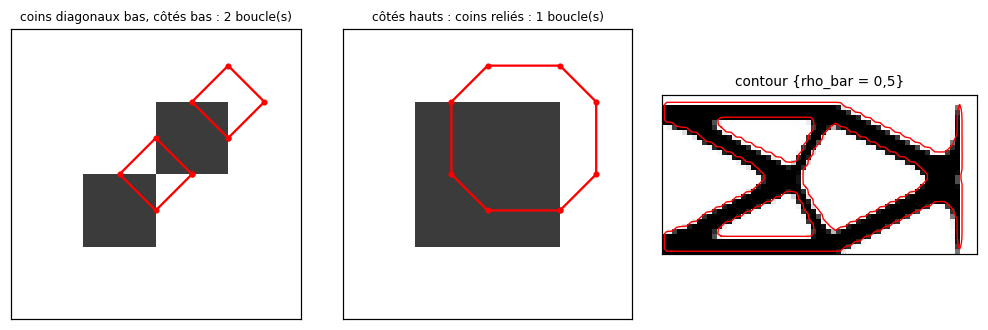

console : 4 boucles (3 trous)
aire du contour 724.3 ; cellules > 0,5 : 734 ; somme de rho_bar : 720.0 ; volume visé : 720.0


In [5]:
# Validation 2 : le cas ambigu. Même quatre coins, centre différent -> deux dessins.
fig, axs = plt.subplots(1, 3, figsize=(9.2, 3.0))
for ax, (nom, vals) in zip(axs, [("coins diagonaux bas, côtés bas", 0.0), ("côtés hauts : coins reliés", 1.0)]):
    ch = np.zeros((4, 4)); ch[1, 1] = ch[2, 2] = 1.0; ch[1, 2] = ch[2, 1] = vals
    ax.imshow(ch.T, origin="lower", cmap="gray_r", vmin=0, vmax=1.3, interpolation="nearest")
    for b in marching_squares(ch, 0.5):
        ax.plot(*np.vstack([b, b[:1]]).T, "r-o", ms=3)
    ax.set_title(f"{nom} : {len(marching_squares(ch, 0.5))} boucle(s)", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
# le contour sur la console optimisée
montre(axs[2], rb, "contour {rho_bar = 0,5}")
for b in marching_squares(rb, 0.5):
    axs[2].plot(*np.vstack([b, b[:1]]).T, "r-", lw=0.9)
plt.tight_layout(); plt.show()

boucles = marching_squares(rb, 0.5)
A_contour = sum(polygon_area(b) for b in boucles)
print(f"console : {len(boucles)} boucles ({sum(polygon_area(b) < 0 for b in boucles)} trous)")
print(f"aire du contour {A_contour:.1f} ; cellules > 0,5 : {(rb > 0.5).sum()} ; somme de rho_bar : {rb.sum():.1f} ; volume visé : {0.4*rb.size:.1f}")

Le contour sur un disque converge vers $\pi r^2$ (l'erreur tombe à moins de 1 % dès $r=15$) et il est **meilleur que le comptage des cellules** à petit rayon. Sur la console, l'aire du contour ($724$) est inférieure de $1{,}3\,\%$ au nombre de cellules seuillées ($734$) : le contour passe par des points d'interpolation qui **coupent les coins** des escaliers. Elle est à $0{,}6\,\%$ au-dessus de $\sum\bar\rho=720$, le volume que l'optimiseur contrôle : l'aire du contour est une bonne estimation du volume de la pièce.

## 3. Marching tetrahedra : la surface 3D, fermée par construction

En 3D, un cube a 8 coins, donc 256 cas, que la symétrie ramène à 15 configurations de base (Lorensen & Cline, 1987). Deux ennuis : la table est longue à écrire et à vérifier, et certaines configurations sont **ambiguës** : deux triangulations possibles pour la même face ; si deux cubes voisins choisissent différemment sur leur face commune, la surface a un **trou**. Les corrections existent (Chernyaev, Lewiner...) mais sont longues.

On prend l'alternative classique : **couper chaque cube en 6 tétraèdres** qui partagent tous la diagonale principale $(0,0,0)$–$(1,1,1)$ (la découpe de Kuhn). Dans un tétraèdre il n'y a que trois cas :
- **1 sommet dedans ou 1 dehors** : un triangle ;
- **2 dedans, 2 dehors** : un quadrilatère (deux triangles).

Pas d'ambiguïté. Et comme la découpe de Kuhn est la même pour tous les cubes, **deux cubes voisins découpent leur face commune de la même façon** : la surface est fermée **par construction**. Le prix : environ deux fois plus de triangles qu'avec les cubes.

Les sommets sont **soudés** : un sommet est identifié par l'arête de la grille qu'il coupe, de sorte que deux triangles voisins le partagent. C'est ce qui permet de tester la topologie. Chaque triangle est orienté pour que sa normale pointe de la matière vers le vide (règle de la main droite).

**Ce qu'on contrôle sur la surface** (`mesh_report`) :
- **arêtes de bord** (utilisées par une seule face = trou) : 0 ;
- **arêtes non-variétés** (utilisées par plus de deux faces) : 0 ;
- **orientation** : chaque arête est parcourue une fois dans chaque sens ;
- **caractéristique d'Euler** $\chi=V-E+F$ : 2 pour une boule, 0 pour un tore (un trou), $2-2g$ en général pour un genre $g$ ;
- **volume signé** (théorème de la divergence), positif si les normales sortent.

In [6]:
def champ_boule(n, r):
    x = np.arange(n) + 0.5 - n / 2
    X, Y, Z = np.meshgrid(x, x, x, indexing="ij")
    return np.clip(0.5 + (r - np.sqrt(X**2 + Y**2 + Z**2)), 0, 1)

print(f"{'rayon':>6} {'triangles':>10} {'watertight':>11} {'Euler':>6} {'volume':>10} {'4/3 pi r^3':>11} {'écart V':>8} {'aire':>9} {'4 pi r^2':>9} {'écart A':>8}")
for r in (4, 8, 16, 32):
    n = int(2.4 * r) + 4
    t = time.time(); V, F = marching_tetrahedra(champ_boule(n, r), 0.5); dt = time.time() - t
    rep = mesh_report(V, F)
    print(f"{r:>6} {rep['n_faces']:>10} {str(rep['watertight']):>11} {rep['euler']:>6} {rep['volume']:>10.1f} {4/3*math.pi*r**3:>11.1f} "
          f"{100*(rep['volume']/(4/3*math.pi*r**3)-1):>7.2f}% {rep['area']:>9.1f} {4*math.pi*r*r:>9.1f} {100*(rep['area']/(4*math.pi*r*r)-1):>7.2f}%   ({dt:.2f} s)")

 rayon  triangles  watertight  Euler     volume  4/3 pi r^3  écart V      aire  4 pi r^2  écart A
     4       1656        True      2      258.1       268.1   -3.74%     207.3     201.1    3.08%   (0.00 s)
     8       7032        True      2     2124.9      2144.7   -0.92%     837.4     804.2    4.13%   (0.02 s)
    16      29040        True      2    17131.8     17157.3   -0.15%    3376.0    3217.0    4.94%   (0.11 s)


    32     115656        True      2   137216.8    137258.3   -0.03%   13488.1   12868.0    4.82%   (0.50 s)


tore : watertight True, Euler 0, volume 5907 (exact 5922)
champ aléatoire 0 : 14300 triangles, watertight True, Euler -340 (plusieurs composantes et cavités), faces dégénérées 0
champ aléatoire 1 : 13604 triangles, watertight True, Euler -292 (plusieurs composantes et cavités), faces dégénérées 0
champ aléatoire 2 : 14196 triangles, watertight True, Euler -306 (plusieurs composantes et cavités), faces dégénérées 0


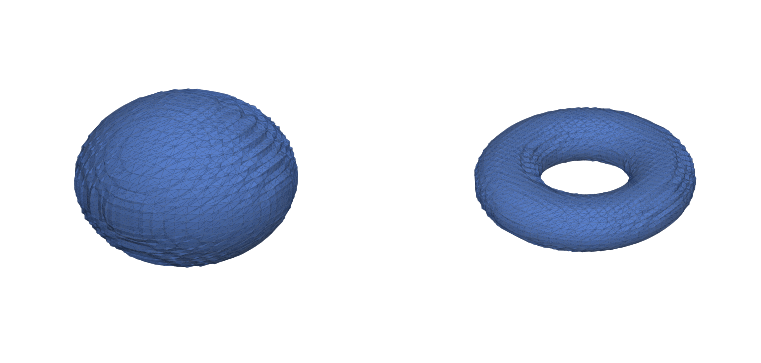

In [7]:
# Un tore : un trou, caractéristique d'Euler 0 ; puis un champ aléatoire (le pire cas pour la topologie)
n = 40; x = np.arange(n) + 0.5 - n / 2
X, Y, Z = np.meshgrid(x, x, x, indexing="ij")
tore = np.clip(0.5 + (5.0 - np.sqrt((np.sqrt(X**2 + Y**2) - 12.0) ** 2 + Z**2)), 0, 1)
Vt, Ft = marching_tetrahedra(tore, 0.5); rt = mesh_report(Vt, Ft)
print(f"tore : watertight {rt['watertight']}, Euler {rt['euler']}, volume {rt['volume']:.0f} (exact {2*math.pi**2*12*25:.0f})")
rng = np.random.default_rng(0)
for k in range(3):
    alea = rng.random((12, 10, 14))
    rr = mesh_report(*marching_tetrahedra(alea, 0.5))
    print(f"champ aléatoire {k} : {rr['n_faces']} triangles, watertight {rr['watertight']}, Euler {rr['euler']} (plusieurs composantes et cavités), faces dégénérées {rr['degenerate']}")

def rend(ax, V, F, couleur=(0.35, 0.5, 0.8), vue=(25, -60)):
    n = face_normals(V, F)
    lum = 0.35 + 0.65 * np.clip(n @ np.array([0.4, -0.5, 0.75]) / np.linalg.norm([0.4, -0.5, 0.75]), 0, 1)
    ax.add_collection3d(Poly3DCollection(V[F], facecolors=np.outer(lum, couleur).clip(0, 1), edgecolor="none"))
    lo, hi = V.min(0), V.max(0); c, w = (lo + hi) / 2, (hi - lo).max() / 2
    ax.set_xlim(c[0]-w, c[0]+w); ax.set_ylim(c[1]-w, c[1]+w); ax.set_zlim(c[2]-w, c[2]+w)
    ax.view_init(*vue); ax.set_axis_off()

fig = plt.figure(figsize=(7.4, 3.4))
rend(fig.add_subplot(121, projection="3d"), *marching_tetrahedra(champ_boule(30, 11), 0.5))
rend(fig.add_subplot(122, projection="3d"), Vt, Ft, vue=(35, -50)); plt.tight_layout(); plt.show()

Sur la boule la surface est fermée, orientée, d'Euler $2$ ; sur le tore d'Euler $0$ ; sur des champs aléatoires elle reste fermée et orientée (la topologie est un cas où la construction est vérifiée mieux par des cas extrêmes que par des beaux cas). Le volume converge vers la valeur analytique (erreur en $1/r^2$). Un point à connaître : l'**aire** est surestimée de plusieurs pour cent à ce découpage, car la triangulation de Kuhn est anisotrope (ses faces suivent des diagonales) ; le volume, lui, converge bien. Pour une pièce, on se fie donc au volume et à la topologie, pas à l'aire.

## 4. Le fichier STL, et une console extrudée

Un STL est la liste des triangles de la surface, sans connectivité : pour chaque facette, une normale et trois sommets. Deux variantes :

- **ASCII** : lisible, lourde ;
- **binaire** : un en-tête de 80 octets, un compteur `uint32`, puis **50 octets par triangle** ($12$ `float32` : normale et trois sommets, plus 2 octets d'attribut). C'est ce qui est écrit par défaut.

Le format n'a **ni unité ni connectivité** : les coordonnées sont celles du maillage (ici le pas de grille `h`, pris en millimètres), et les sommets sont écrits en `float32`, ce qui limite la précision à $10^{-7}$ relatif. Les normales sont recalculées à partir de l'ordre des sommets : l'orientation du maillage est donc ce qui compte.

On extrude la console du §1 sur $6$ mm d'épaisseur ($6$ couches suivant $y$, comme une pièce plate imprimée debout sur sa tranche), on en extrait la surface (une cellule = 1 mm), on l'écrit en STL, et on la relit.

In [8]:
epaisseur = 6
champ3d = extrude(rb, epaisseur)                      # (nx, ny, nz) : axe de fabrication z en dernier
V, F = marching_tetrahedra(champ3d, 0.5, h=(1.0, 1.0, 1.0))
rep = mesh_report(V, F)
A2 = sum(polygon_area(b) for b in marching_squares(rb, 0.5))
print(f"{rep['n_vertices']} sommets, {rep['n_faces']} triangles, watertight {rep['watertight']}, Euler {rep['euler']}, faces dégénérées {rep['degenerate']}")
print(f"volume du maillage {rep['volume']:.1f} mm³ ; aire du contour 2D × épaisseur = {A2*epaisseur:.1f} mm³ ; cellules > 0,5 × 1 mm³ = {(champ3d > 0.5).sum()}")
print(f"boîte : {V.min(0).round(2)} -> {V.max(0).round(2)} mm")

dossier = Path(tempfile.mkdtemp())
for binaire in (True, False):
    chemin = dossier / ("console_bin.stl" if binaire else "console_ascii.stl")
    write_stl(chemin, V, F, binary=binaire, name="console")
    V2, F2, N2 = read_stl(chemin); r2 = mesh_report(V2, F2)
    print(f"{chemin.name:>17} : {chemin.stat().st_size/1e3:7.1f} ko ; relu : {len(F2)} triangles, watertight {r2['watertight']}, "
          f"volume {r2['volume']:.1f} ; normales unitaires {np.allclose(np.linalg.norm(N2, axis=1), 1, atol=1e-5)}")
print("taille binaire attendue 84 + 50 x triangles =", 84 + 50 * len(F), "octets")
print((dossier / "console_ascii.stl").read_text()[:330])

14936 sommets, 29880 triangles, watertight True, Euler -4, faces dégénérées 0
volume du maillage 4268.4 mm³ ; aire du contour 2D × épaisseur = 4345.6 mm³ ; cellules > 0,5 × 1 mm³ = 4404
boîte : [0. 0. 0.] -> [60.  6. 30.] mm
  console_bin.stl :  1494.1 ko ; relu : 29880 triangles, watertight True, volume 4268.4 ; normales unitaires True


console_ascii.stl :  8519.0 ko ; relu : 29880 triangles, watertight True, volume 4268.4 ; normales unitaires True
taille binaire attendue 84 + 50 x triangles = 1494084 octets
solid console
  facet normal 0.000000000e+00 -0.000000000e+00 -1.000000000e+00
    outer loop
      vertex 5.000000000e-01 5.000000000e-01 0.000000000e+00
      vertex 5.000000000e-01 0.000000000e+00 0.000000000e+00
      vertex 0.000000000e+00 0.000000000e+00 0.000000000e+00
    endloop
  endfacet
  facet normal 0.000000000e+00


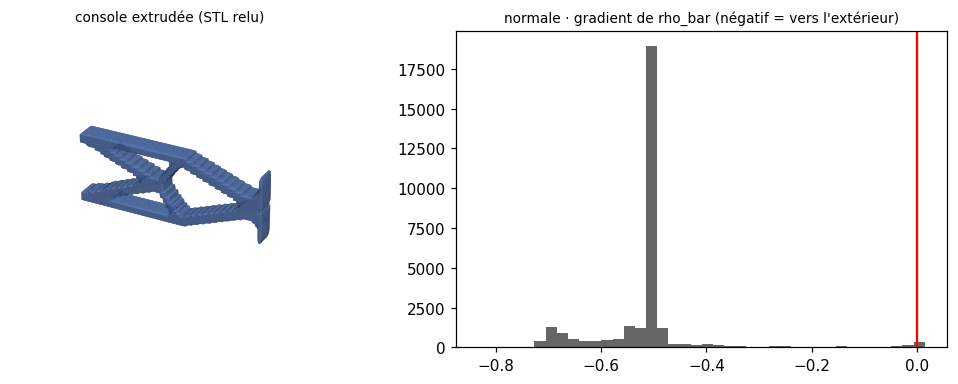

facettes à gradient non nul : 29504 ; normale sortante (produit scalaire < 0) : 99.6 %


In [9]:
fig = plt.figure(figsize=(9.6, 3.6))
ax = fig.add_subplot(121, projection="3d"); rend(ax, V, F, vue=(28, -62)); ax.set_title("console extrudée (STL relu)", fontsize=9)
# la normale de chaque facette pointe-t-elle vers l'extérieur ? On teste avec le gradient de rho_bar (qui pointe vers la matière)
n = face_normals(V, F); ctr = V[F].mean(1)
idx = np.clip(np.floor(ctr).astype(int), 0, np.array(champ3d.shape) - 1)
g = np.stack(np.gradient(np.pad(champ3d, 1), axis=(0, 1, 2)), -1)[tuple((idx + 1).T)]
scal = np.einsum("ij,ij->i", n, g)
ax2 = fig.add_subplot(122); ax2.hist(scal[np.linalg.norm(g, axis=1) > 0.05], bins=40, color="0.4"); ax2.axvline(0, color="r")
ax2.set_title("normale · gradient de rho_bar (négatif = vers l'extérieur)", fontsize=9); plt.tight_layout(); plt.show()
m = np.linalg.norm(g, axis=1) > 0.05
print(f"facettes à gradient non nul : {m.sum()} ; normale sortante (produit scalaire < 0) : {100*(scal[m] < 0).mean():.1f} %")

La surface extrudée est **fermée et orientée**. Son Euler vaut $-4=2-2g$ : une seule pièce avec $g=3$ trous traversants, les trois trous du contour 2D. Son volume ($4268$) est à $1{,}8\,\%$ sous l'aire du contour fois l'épaisseur ($4346$) : les deux extractions (carrés, puis tétraèdres) coupent les coins de façon un peu différente. Le fichier relu redonne la même pièce. La quasi-totalité des normales pointent vers l'extérieur (les rares exceptions sont dans des cellules où le gradient estimé par différences finies est peu fiable).

Ce que cela garantit : un *slicer* acceptera ce fichier. Ce que cela ne garantit pas : que la pièce soit **imprimable**, c'est le sujet du paragraphe suivant.

## 5. L'épaisseur minimale : rayon du filtre contre largeur réelle

Une buse de $0{,}4$ mm dépose un trait d'environ $0{,}4$ à $0{,}5$ mm ; une membrure plus fine que **deux traits** (moins de $\approx0{,}8$ mm) n'a pas de cœur et casse. Le rayon $R$ du filtre de densité (notebook 9) est un paramètre de **conception**, pas une largeur mesurée : la largeur des membrures qui en résulte dépend aussi de la projection et de la compétition avec le volume. On la mesure sur la pièce binarisée.

**L'ouverture morphologique.** On érode la pièce avec un disque de rayon $r$ (on garde les cellules dont tout le disque est dans la pièce), puis on dilate avec le même disque : on retrouve l'union de tous les disques de rayon $r$ qui tiennent **entièrement** dans la matière. Ce qui disparaît est trop fin pour contenir un disque de rayon $r$. La fraction de matière perdue, `thin_fraction`, vaut $0$ pour une pièce dont toutes les membrures ont une largeur $\ge2r$, et grandit vite pour des membrures plus fines. Les coins convexes sont toujours arrondis par l'ouverture : quelques pour cent de la matière sont perdus même sur une pièce parfaite (le test unitaire fixe $<8\,\%$ sur une barre de 10 cellules).

On optimise la console pour trois rayons $R$ et on mesure la courbe $r\mapsto$ `thin_fraction`. On prend une fraction volumique de $0{,}3$ plutôt que $0{,}4$ : avec peu de matière les membrures sont fines et $R$ devient le paramètre qui compte (à $0{,}4$, la largeur est fixée par le volume et les trois rayons donnent presque la même pièce, ce qu'on a mesuré en préparant ce notebook).

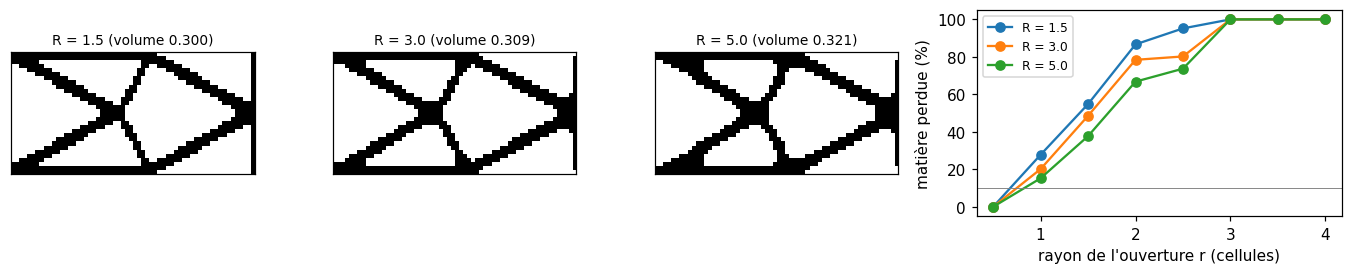

    R r=1.0  r=1.5  r=2.0  r=2.5  r=3.0  r=3.5  r=4.0 
  1.5   27.8   54.8   86.7   95.2  100.0  100.0  100.0   (% de matière perdue)
  3.0   20.1   48.6   78.4   80.2  100.0  100.0  100.0   (% de matière perdue)
  5.0   15.2   37.7   66.8   73.7  100.0  100.0  100.0   (% de matière perdue)


In [10]:
rayons_R = (1.5, 3.0, 5.0)
resR = {}
for R in rayons_R:
    pbR, rbR = optimise_console(R=R, volfrac=0.3)
    resR[R] = rbR
rs = np.arange(0.5, 4.01, 0.5)
fig, axs = plt.subplots(1, 4, figsize=(12.4, 2.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
courbes = {}
for ax, R in zip(axs, rayons_R):
    montre(ax, resR[R] > 0.5, f"R = {R} (volume {(resR[R] > 0.5).mean():.3f})")
    courbes[R] = [thin_fraction(resR[R] > 0.5, r) for r in rs]
for R in rayons_R: axs[3].plot(rs, 100 * np.array(courbes[R]), "o-", label=f"R = {R}")
axs[3].axhline(10, color="gray", lw=0.6); axs[3].set_xlabel("rayon de l'ouverture r (cellules)"); axs[3].set_ylabel("matière perdue (%)")
axs[3].legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'R':>5} " + " ".join(f"r={r:<4}" for r in rs[1:]))
for R in rayons_R:
    print(f"{R:>5} " + " ".join(f"{100*c:>6.1f}" for c in courbes[R][1:]) + "   (% de matière perdue)")

**Lecture.** Un rayon de filtre plus grand donne des membrures plus larges, mais **faiblement** et sans valeur garantie : la matière perdue pour une ouverture de rayon $1$ (largeur $2$ cellules) passe de $28\,\%$ ($R=1{,}5$) à $20\,\%$ ($R=3$) puis $15\,\%$ ($R=5$), et il en reste. Le rayon $R$ est un rayon de **support** du cône, sa largeur utile est plus petite, et la projection raidit la frontière sans élargir. À fraction volumique $0{,}4$ le volume fixe la largeur et $R$ ne joue presque pas. Règle pratique pour le projet : **ne pas lire $R$ comme une largeur minimale**, mesurer la largeur sur la pièce extraite avec `thin_fraction` et exiger que la perte pour $r=$ (deux largeurs de buse)/2 soit faible. Le filtre contrôle les barres de façon indirecte (FORMALISM H : il ne contrôle pas les trous).

Ce contrôle regarde la **matière** ; une fente trop étroite (un trou fin entre deux membrures) se contrôle de la même façon sur le **complément** de la pièce : `thin_fraction(~solid, r)`.

## 6. Ce que coûtent le seuillage et le lissage

La compliance que l'optimiseur minimise est celle de $\bar\rho$ **continu avec SIMP** ($p=3$) : les cellules grises sont pénalisées et rigidifient mal. La pièce qu'on imprime n'a pas de gris : chaque point est plein ou vide, avec la matière à pleine rigidité. On compare, sur la même console :

1. $\bar\rho$ continu, SIMP $p=3$ : la valeur de l'optimiseur ;
2. la pièce **seuillée à $0{,}5$**, sur la **même grille**, rigidité de la matière pleine ($p=1$) ;
3. la pièce seuillée sur une grille **raffinée** ($\times2$, $\times3$, $\times4$) après interpolation bilinéaire de $\bar\rho$ : c'est la région délimitée par le contour lissé du §2, et c'est ce qu'un STL décrit réellement. La charge est répartie, donc la compliance converge avec le maillage.

In [11]:
C1 = compliance_fe(rb, p=3.0)
C2 = compliance_fe((rb > 0.5).astype(float))
print(f"{'pièce':>40} {'volume':>8} {'compliance':>11} {'écart / optimiseur':>19}")
print(f"{'1. rho_bar continu, SIMP p=3':>40} {rb.mean():>8.4f} {C1:>11.2f} {'':>19}")
print(f"{'2. seuillée à 0,5, même grille':>40} {(rb > 0.5).mean():>8.4f} {C2:>11.2f} {100*(C2/C1-1):>18.1f}%")
for z in (2, 3, 4):
    up = ndimage.zoom(rb, z, order=1, grid_mode=True, mode="nearest")
    b = (up > 0.5).astype(float)
    t = time.time(); C3 = compliance_fe(b, h=(1.0 / z, 1.0 / z))
    print(f"{f'3. contour lissé, grille x{z}':>40} {b.mean():>8.4f} {C3:>11.2f} {100*(C3/C1-1):>18.1f}%   ({time.time()-t:.1f} s)")
A_contour = sum(polygon_area(bb) for bb in marching_squares(rb, 0.5))
print(f"\naire du contour / aire totale : {A_contour/rb.size:.4f}  (volume visé 0,4000)")

                                   pièce   volume  compliance  écart / optimiseur
            1. rho_bar continu, SIMP p=3   0.4000       83.65                    
          2. seuillée à 0,5, même grille   0.4078       80.92               -3.3%
             3. contour lissé, grille x2   0.4008       83.12               -0.6%   (0.1 s)


             3. contour lissé, grille x3   0.4064       80.89               -3.3%   (0.2 s)


             3. contour lissé, grille x4   0.4032       81.51               -2.6%   (0.4 s)

aire du contour / aire totale : 0.4024  (volume visé 0,4000)


**Lecture.**
- La pièce binaire est **un peu plus raide** que ce que l'optimiseur évaluait (compliance de quelques pour cent plus basse) : la pénalisation SIMP sous-estime la rigidité des cellules grises, et le seuil à $0{,}5$ en garde un peu plus de la moitié (volume $0{,}408$ au lieu de $0{,}400$). Le gain est donc en partie du **volume en plus**, pas de la géométrie.
- Le raffinement et le contour lissé **ne changent pas** la compliance de plus de $3\,\%$ (de $-3{,}3\,\%$ à $-0{,}6\,\%$ par rapport à l'optimiseur, selon la grille) : l'extraction ne détruit pas ce que l'optimiseur a trouvé. Les écarts entre grilles ($\times2$, $\times3$, $\times4$) sont de l'ordre de la variation du volume seuillé, pas d'une tendance de convergence.
- Le volume de la pièce extraite est à **$\pm1{,}5\,\%$** du volume visé selon l'extraction ($+0{,}6\,\%$ pour le contour 2D, $-1{,}2\,\%$ pour le maillage 3D) ; le seuil binaire sur la grille donne $+2\,\%$. Ces écarts se rattrapent en pesant la pièce finale.
- On a vu au §1 que **le seuil à $0{,}5$ est la seule option raisonnable** : ni plus haut (la structure se casse) ni ajusté au volume.

**Ce qu'on n'a pas mesuré** : la pièce extraite n'est évaluée ici que pour la rigidité. Sa résistance, son état de surface et l'effet d'escalier de l'impression couche par couche ne sont pas dans ce modèle.

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| Après continuation $\beta$, $\bar\rho$ est presque binaire ; le seuil se prend à $\eta=0{,}5$ ; la compliance varie doucement avec le seuil, sauf si des nœuds chargés perdent toutes leurs cellules (artefact du modèle de charge) | §1 |
| Marching squares : 16 cas, interpolation linéaire, selle tranchée par le centre, boucles orientées ; aire signée = aire de la matière (trous négatifs), $<1\,\%$ d'erreur dès $r=15$ | `marching_squares`, `polygon_area`, C-EXP-01 |
| Tétraèdres de Kuhn : pas d'ambiguïté, surface fermée par construction, sommets soudés ; Euler 2 (boule) et 0 (tore) ; volume qui converge | `marching_tetrahedra`, `mesh_report`, C-EXP-02, 03 |
| L'aire est surestimée de plusieurs % (triangulation anisotrope) : se fier au volume et à la topologie | §3 |
| STL binaire : $84+50F$ octets, normales sortantes, relecture identique ; ni unité ni connectivité | `write_stl`, `read_stl`, C-EXP-04 |
| Largeur minimale : ouverture morphologique ; $R$ élargit les membrures sans garantir de valeur (à volume $0{,}3$ : $28\,\%$, $20\,\%$, $15\,\%$ de matière trop fine à $r=1$ pour $R=1{,}5$, $3$, $5$) | `thin_fraction`, C-EXP-05 |
| Pièce extraite : compliance à $3\,\%$ de la valeur de l'optimiseur ; volume à $\pm1{,}5\,\%$ du volume visé selon l'extraction | §6 |

**Limites à retenir.**
- **L'axe de fabrication n'est pas contrôlé par l'extraction** : c'est l'orientation de la grille. L'auto-support (leçon 12) doit être vérifié sur la pièce **seuillée**, pas seulement sur $\bar\rho$.
- **Le contour lisse n'est pas la forme imprimée** : le *slicer* découpe en couches et ajoute son propre effet d'escalier et ses motifs de remplissage.
- **Le STL n'a pas d'unité** : le projet doit fixer une convention (ici : millimètres) et la vérifier dans le *slicer*.
- **Un maillage fermé n'est pas une pièce solide** : il peut contenir des cavités internes fermées (invisibles de l'extérieur, piégeant de la poudre ou de la résine en procédé fluide, sans effet sur le FDM mais à repérer). L'Euler du maillage ne les distingue pas des trous traversants ; il faut compter les composantes.
- **Les mesures viennent d'une console 2D** extrudée ; un vrai 3D optimisé n'a pas été extrait ici.

**Pour expérimenter.** (i) Au §1, appliquez la charge d'abord au seul nœud du milieu du bord : l'artefact des nœuds orphelins change-t-il ? (ii) Au §3, remplacez le tétraèdre de Kuhn par le cube de 8 coins pour une seule configuration ambiguë et voyez le trou : c'est l'objet de la table de Chernyaev. (iii) Au §5, mesurez `thin_fraction(~solid, r)` pour les trous : quelle largeur minimale ? (iv) Au §6, ajoutez le filtre de surplomb du notebook 12 à l'optimisation : la pièce extraite est-elle auto-supportante après seuillage à $0{,}5$ ? (testez avec `exact_support`).

*Suite : leçon 14 (écoulement potentiel). Voir le [plan des leçons](README.md).*